# HW3 : Evaluating Binary Classifiers



In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

from sklearn.model_selection import train_test_split

RANDOM_SEED = 8675309

# Starter Code
## Data loading and cleaning

In [43]:
# You may need to adjust the path
diabetes_readmit = pd.read_csv("diabetic_readmission.csv")

# Remove target variable (biopsy) and other diagnostic tests we're not using
X_df = diabetes_readmit.drop(columns=["readmitted", "encounter_id", "patient_nbr"])

# We are only trying to predict if they were readmitted within 30 days
readmitted_mapping = {'<30': 1, '>30': 0, 'NO': 0}
diabetes_readmit.readmitted = diabetes_readmit.readmitted.map(readmitted_mapping)
y = diabetes_readmit.readmitted

In [44]:
diabetes_readmit.describe()

,Unnamed: 0,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted
count,14250.000000,1.425000e+04,1.425000e+04,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000,14250.000000
mean,51079.510947,1.656705e+08,5.431133e+07,2.021544,3.732281,5.708842,4.393825,42.911298,1.345965,16.031789,0.391298,0.260211,0.773895,7.380912,0.080000
std,29205.871675,1.020231e+08,3.856413e+07,1.445343,5.348948,4.018773,3.007580,20.064738,1.701749,8.195488,1.347276,1.234892,1.638831,1.949795,0.271303
min,8.000000,1.252200e+04,3.780000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,25876.500000,8.582953e+07,2.342251e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000,0.000000
50%,50955.500000,1.525163e+08,4.578918e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000,0.000000
75%,76439.000000,2.307733e+08,8.794194e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000,0.000000
max,101765.000000,4.438672e+08,1.892578e+08,8.000000,28.000000,22.000000,14.000000,120.000000,6.000000,74.000000,40.000000,64.000000,21.000000,16.000000,1.000000


Missing data is represented by "?", which we need to convert to `NaN`. 

In [45]:
#Replace all of the "?" with NaN (not a number)
X_df = X_df.replace('?', np.nan)

X_df.dtypes

Unnamed: 0                   int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride                 object
acetohexamide       

We need to make an initial split so we don't make decisions based on missing data using the test set. Notice we include the `stratify` keyword, which splits the data such that there are equal proportions of each class in the training and testing sets. This is especially important for unbalanced datasets like this one. 

In [46]:
# Create a development/test split
X_dev, X_test, y_dev, y_test = train_test_split(
    X_df, y, test_size=0.10, random_state=RANDOM_SEED, stratify=y
)

### Missing Data

This dataset contains missing data. We'll deal with missing values in the pipeline, but let's get an initial feel for the percent of missing data per feature. Note that we're not using the test set to perform any missing data calculations or decisions. 

In [47]:
missing_counts = X_dev.isnull().sum()
missing_percentage = (X_dev.isnull().sum() / len(X_dev)) * 100

# Combine into a clean table
missing_info = pd.concat([missing_counts, missing_percentage], axis=1, keys=['Total Missing', 'Percent'])
print(missing_info.sort_values(by='Percent', ascending=False).head(10))

                   Total Missing    Percent
weight                     12406  96.732943
max_glu_serum              12148  94.721248
A1Cresult                  10685  83.313840
medical_specialty           6244  48.686160
payer_code                  5044  39.329435
race                         256   1.996101
diag_3                       173   1.348928
diag_2                        39   0.304094
diag_1                         2   0.015595
Unnamed: 0                     0   0.000000


We have some features that are almost entirely missing. We'll be conservative since we have so many features and drop everything that has 80% missing data or more. Payer code and medical specialty aren't missing that much data, but as categorical features with a lot of categories they are difficult to impute, so we could consider dropping them as well.  

In [48]:
cols_to_drop = X_dev.columns[X_dev.isna().mean() > 0.80].tolist()
X_dev = X_dev.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop)

### Categorical data

The age column is stored in 10-year increments. We don't want to treat this as a pure categorical variable, as it would obfuscate that 20 is closer to 30 than it is to 60, for instance. Instead, let's convert age to be the mean of each interval. 

In [49]:
# Create a dictionary mapping the exact strings in the dataset to their midpoints
age_mapping = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}
X_dev.age = X_dev.age.map(age_mapping)
X_test.age = X_test.age.map(age_mapping)

Now let's grab all other categorical columns, those either marked as categories or as objects (strings) by pandas. We'll actually do the encoding inside the pipeline using sklearn's `OneHotEncoder`. There are lots of other options for dealing with the categorical data we could consider, but this is the easiest approach. 

In [50]:
categorical_cols = X_dev.select_dtypes(include=['object', 'category']).columns

Finally, we'll further split out a validation set to use for hyperparamter selection. 

In [51]:
# Further split the development set into a training and validation set
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.2, random_state=RANDOM_SEED, stratify=y_dev
)

## Pipelines

Both Logistic Regression (with regularization) and K-Nearest Neighbors require feature scaling to work correctly. These pipelines ensures that missing values are imputed and features are standardized *after* any data splitting to prevent data leakage.

In [52]:
"""
Creates a sklearn pipeline for logistic regression with imputation and rescaling steps.
C is the inverse regularization strength, smaller values resulting in higher regularization
Passes in l1_ratio=0 for L2-regularized logistic regression and uses the lbfgs solver.
"""

# Since we only want to apply the OneHotEncoder to some columns, we have to put it in a ColumnTransformer.
categories_transformer = ColumnTransformer(
    transformers=[ 
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ], 

    # Without this line sklearn drops all columns not transformed
    remainder='passthrough')

def make_logit_knnimpute(C=1.0, k=5):
    pipeline = Pipeline(
        steps=[
         ('cat_encoder', categories_transformer),
         ('imputer', KNNImputer(n_neighbors=k)),
         ('rescaler', MinMaxScaler()),
         ('logit', LogisticRegression(solver="lbfgs", l1_ratio=0, C=C, max_iter=1000))
        ])
    
    # Return the constructed pipeline
    return pipeline

def make_knn_knnimpute(k_model=5, k_impute=5):
    pipeline = Pipeline(
        steps=[
         ('cat_encoder', categories_transformer),
         ('imputer', KNNImputer(n_neighbors=k_impute)),
         ('rescaler', MinMaxScaler()),
         ('knn', KNeighborsClassifier(n_neighbors=k_model))
        ])
    
    # Return the constructed pipeline
    return pipeline

# Your Code

Good luck!

In [53]:
#question 1 a
# retrieves the postive and negative class proportions based on 0 or 1
pos_class_prop = (y_dev == 1).mean()
neg_class_prop = (y_dev == 0).mean()

print(f"positive class (patients readmitted within 30 days): {pos_class_prop:.3f}")
print(f"negative class (petients not readmitted within 30 days): {neg_class_prop:.3f}")

# Accuracy of a baseline model that always predicts the negative class
baseline_acc = neg_class_prop
print(f"baseline acc for neg class: {baseline_acc:.3f}")

positive class (patients readmitted within 30 days): 0.080
negative class (petients not readmitted within 30 days): 0.920
baseline acc for neg class: 0.920


In [54]:
#question 1b

C_grid = np.logspace(-4, 4, 10)
k_grid = range(1, 6, 2)

logit_results = []

for k in k_grid:
    for C in C_grid:
        #creates and trains the model using the pipeline provided
        model = make_logit_knnimpute(C=C, k=k)
        model.fit(X_train, y_train)

        # predicts probabilities for the positive class 
        y_val_prob = model.predict_proba(X_val)[:, 1]

        # find validation using roc-auc
        auc = roc_auc_score(y_val, y_val_prob)
        logit_results.append({"C": C,"k_impute": k,"val_auc": auc})

        print(f"C={C:.3g}, k_impute={k}, AUC={auc:.3f}")


logit_results = sorted(
    logit_results,
    key=lambda result: (
        -result["val_auc"],
        result["k_impute"],
        result["C"]
    )
)

best_logit = logit_results[0]

print("\nlogit model best:")
print(f"Bbest C: {best_logit['C']:.3g}")
print(f"Bbest impt n_neighbors: {best_logit['k_impute']}")
print(f"best validation AUCROC: {best_logit['val_auc']:.3f}")

C=0.0001, k_impute=1, AUC=0.749


/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if w

C=0.000774, k_impute=1, AUC=0.776


/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWa

C=0.00599, k_impute=1, AUC=0.864


...

/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWa

C=167, k_impute=5, AUC=0.947


/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWa

C=1.29e+03, k_impute=5, AUC=0.942
C=1e+04, k_impute=5, AUC=0.942

logit model best:
Bbest C: 0.359
Bbest impt n_neighbors: 1
best validation AUCROC: 0.966


/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [55]:
# question 1c:

k_knn_grid = range(1, 26, 2)
k_imp_grid = range(1, 6, 2)

knn_results = []

for k_impute in k_imp_grid:
    for k_model in k_knn_grid:
        model = make_knn_knnimpute(
            k_model=k_model,
            k_impute=k_impute
        )
        model.fit(X_train, y_train)

        y_val_prob = model.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, y_val_prob)

        knn_results.append({"k_model": k_model,"k_impute": k_impute, "val_auc": auc})

        print(f"k_model = {k_model}, " f"k_impute={k_impute}, AUC={auc:.3f}")

knn_results = sorted(
    knn_results,
    key=lambda result: (-result["val_auc"],result["k_impute"],result["k_model"])
)

best_knn = knn_results[0]

print("\nbest KNN model:")
print(f"bbest classifier n_neighbors: {best_knn['k_model']}")
print(f"best impt n_neighbors: {best_knn['k_impute']}")
print(f"best Aauroc validation score: {best_knn['val_auc']:.3f}")

k_model = 1, k_impute=1, AUC=0.696
k_model = 3, k_impute=1, AUC=0.748
k_model = 5, k_impute=1, AUC=0.765
k_model = 7, k_impute=1, AUC=0.788
k_model = 9, k_impute=1, AUC=0.790
k_model = 11, k_impute=1, AUC=0.799
k_model = 13, k_impute=1, AUC=0.802
k_model = 15, k_impute=1, AUC=0.805
k_model = 17, k_impute=1, AUC=0.810
k_model = 19, k_impute=1, AUC=0.804
k_model = 21, k_impute=1, AUC=0.818
k_model = 23, k_impute=1, AUC=0.819
k_model = 25, k_impute=1, AUC=0.818
k_model = 1, k_impute=3, AUC=0.696
k_model = 3, k_impute=3, AUC=0.748
k_model = 5, k_impute=3, AUC=0.765
k_model = 7, k_impute=3, AUC=0.788
k_model = 9, k_impute=3, AUC=0.790
k_model = 11, k_impute=3, AUC=0.799
k_model = 13, k_impute=3, AUC=0.802
k_model = 15, k_impute=3, AUC=0.805
k_model = 17, k_impute=3, AUC=0.810
k_model = 19, k_impute=3, AUC=0.804
k_model = 21, k_impute=3, AUC=0.818
k_model = 23, k_impute=3, AUC=0.819
k_model = 25, k_impute=3, AUC=0.818
k_model = 1, k_impute=5, AUC=0.696
k_model = 3, k_impute=5, AUC=0.748
k_mo

/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if w

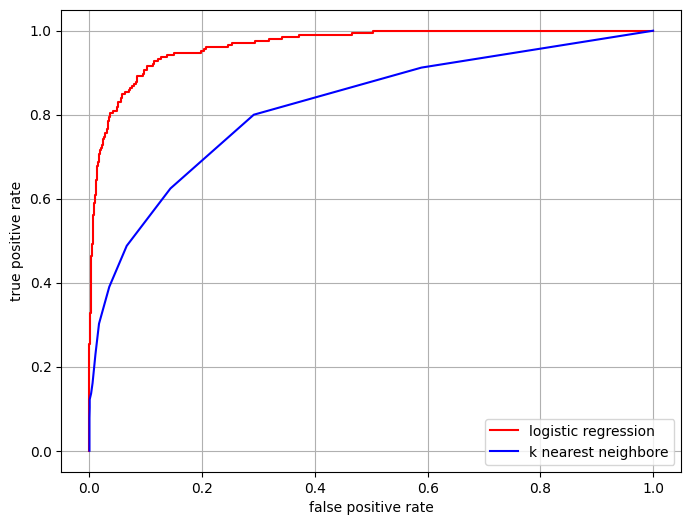

In [56]:

#question 2a

best_logit_model = make_logit_knnimpute(C=best_logit["C"],k=best_logit["k_impute"])
best_logit_model.fit(X_train, y_train)

best_knn_model = make_knn_knnimpute(
    k_model=best_knn["k_model"],
    k_impute=best_knn["k_impute"]
)
best_knn_model.fit(X_train, y_train)

logit_val_prob = best_logit_model.predict_proba(X_val)[:, 1]
knn_val_prob = best_knn_model.predict_proba(X_val)[:, 1]

logit_fpr, logit_tpr, logit_thresholds = roc_curve(
    y_val, logit_val_prob
)
knn_fpr, knn_tpr, knn_thresholds = roc_curve(
    y_val, knn_val_prob
)

#plot
plt.figure(figsize=(8, 6))
plt.plot(logit_fpr, logit_tpr, "r-", label="logistic regression")
plt.plot(knn_fpr, knn_tpr, "b-", label="k nearest neighbore")

plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend()
plt.grid(True)
plt.show()

In [57]:
#question 2b


def select_threshold(fpr, tpr, thresholds):
    eligible = np.where(fpr <= 0.15)[0]

    # Maximize TPR; break ties by choosing the smaller FPR
    best_idx = sorted(
        eligible,
        key=lambda i: (-tpr[i], fpr[i])
    )[0]

    return {
        "threshold": thresholds[best_idx],
        "TPR": tpr[best_idx],
        "TNR": 1 - fpr[best_idx],
        "FPR": fpr[best_idx]
    }

logit_choice = select_threshold(
    logit_fpr, logit_tpr, logit_thresholds
)
knn_choice = select_threshold(
    knn_fpr, knn_tpr, knn_thresholds
)

print("LR:")
print(f"Threshold: {logit_choice['threshold']:.3f}")
print(f"TNR: {logit_choice['TNR']:.3f}")
print(f"TPR: {logit_choice['TPR']:.3f}")

print("\n knn:")
print(f"Threshold: {knn_choice['threshold']:.3f}")
print(f"TNR: {knn_choice['TNR']:.3f}")
print(f"TPR: {knn_choice['TPR']:.3f}")

#comparison would be good
if logit_choice["TPR"] > knn_choice["TPR"]:
    better_model = "logit"
elif knn_choice["TPR"] > logit_choice["TPR"]:
    better_model = "knn"
elif logit_choice["TNR"] >= knn_choice["TNR"]:
    better_model = "logit"
else:
    better_model = "knn"




LR:
Threshold: 0.071
TNR: 0.863
TPR: 0.941

 knn:
Threshold: 0.130
TNR: 0.856
TPR: 0.624


In [58]:


#use better model in this case
if better_model == "logit":
    final_model = make_logit_knnimpute(
        C=best_logit["C"],
        k=best_logit["k_impute"]
    )
    chosen_threshold = logit_choice["threshold"]

else:
    final_model = make_knn_knnimpute(k_model=best_knn["k_model"],k_impute=best_knn["k_impute"])
    chosen_threshold = knn_choice["threshold"]

# fit onto dev data
final_model.fit(X_dev, y_dev)

#predict
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)


cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("conf matrix")
print(pd.DataFrame(cm,index=["actual neg (0)", "actual pos (1)"],columns=["pred neg (0)", "pred pos (1)"]))

print(f"\n TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

conf matrix
                pred neg (0)  pred pos (1)
actual neg (0)          1140           171
actual pos (1)             5           109

 TN: 1140
FP: 171
FN: 5
TP: 109


/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if w

In [59]:

# 3A: Baseline costs

c_fn = 20000
c_fp = 500
population = 100000


base_rate = (y_val == 1).mean()

cost_all_positive = population * (1 - base_rate) * c_fp

cost_all_negative = population * base_rate * c_fn

print(f"validation positive base rate: {base_rate:.3f}")


print(f"vost of predicting all positive: ${cost_all_positive:,.3f}")
print(f"vost of predicting all negative: ${cost_all_negative:,.3f}")

validation positive base rate: 0.080
vost of predicting all positive: $46,003,898.635
vost of predicting all negative: $159,844,054.581


In [60]:

#3b

def find_min_cost_threshold(fpr, tpr, thresholds, base_rate):
    fnr = 1 - tpr

    fn_fraction = fnr * base_rate
    fp_fraction = fpr * (1 - base_rate)

 
    costs = population * (fn_fraction * c_fn + fp_fraction * c_fp)

    best_idx = np.argmin(costs)

    return {
        "threshold": thresholds[best_idx],
        "tpr": tpr[best_idx],
        "fpr": fpr[best_idx],
        "tnr": 1 - fpr[best_idx],
        "cost": costs[best_idx],
        "predicted_intervention_rate": (
            tpr[best_idx] * base_rate
            + fpr[best_idx] * (1 - base_rate)
        )
    }


logit_cost_choice = find_min_cost_threshold(
    logit_fpr, logit_tpr, logit_thresholds, base_rate
)

knn_cost_choice = find_min_cost_threshold(
    knn_fpr, knn_tpr, knn_thresholds, base_rate
)

print("logggit")
for key, value in logit_cost_choice.items():
    print(f"{key}: {value:.6f}" if key == "threshold"
          else f"{key}: {value:.4f}" if key in ("tpr", "fpr", "tnr")
          else f"{key}: {value:.4f}" if key == "predicted_intervention_rate"
          else f"{key}: ${value:,.2f}")


#debug
print("\nKNN")
for key, value in knn_cost_choice.items():
    print(f"{key}: {value:.6f}" if key == "threshold"
          else f"{key}: {value:.3f}" if key in ("tpr", "fpr", "tnr")
          else f"{key}: {value:.4f}" if key == "predicted_intervention_rate"
          else f"{key}: ${value:,.2f}")

best_cost_model = (
    "Logistic Regression"
    if logit_cost_choice["cost"] <= knn_cost_choice["cost"]
    else "KNN"
)
best_cost_choice = (
    logit_cost_choice
    if best_cost_model == "Logistic Regression"
    else knn_cost_choice
)


logggit
threshold: 0.067302
tpr: 0.9463
fpr: 0.1504
tnr: 0.8496
cost: $15,497,076.02
predicted_intervention_rate: 0.2140

KNN
threshold: 0.043478
tpr: 0.912
fpr: 0.589
tnr: 0.411
cost: $41,130,604.29
predicted_intervention_rate: 0.6148


In [61]:

#3c

new_base_rate = base_rate / 2

logit_new_choice = find_min_cost_threshold(
    logit_fpr, logit_tpr, logit_thresholds, new_base_rate
)

knn_new_choice = find_min_cost_threshold(
    knn_fpr, knn_tpr, knn_thresholds, new_base_rate
)



print("\nlogit:")
print(f"threshold: {logit_new_choice['threshold']:.3f}")
print(f"TPR: {logit_new_choice['tpr']:.3f}")
print(f"FPR: {logit_new_choice['fpr']:.3f}")
print(f"tstimated cost: ${logit_new_choice['cost']:,.3f}")

print("\nKNN ")
print(f"threshold: {knn_new_choice['threshold']:.3f}")
print(f"TPR: {knn_new_choice['tpr']:.3f}")
print(f"FPR: {knn_new_choice['fpr']:.3f}")
print(f"estimated cost: ${knn_new_choice['cost']:,.3f}")




logit:
threshold: 0.076
TPR: 0.937
FPR: 0.128
tstimated cost: $11,190,508.640

KNN 
threshold: 0.087
TPR: 0.800
FPR: 0.292
estimated cost: $29,978,194.073
